# Independent kidney cohort: zero-shot transfer of frozen representations

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Reviewer comment on Fig. 6c-e: alternative strategies for the zero-shot kidney
experiment. Every model is trained on Cristiano cancer vs healthy (538 samples) with
the outer 5-fold split of the published LEAF-1 MIL, one model per fold, and applied
frozen to the independent kidney cohort (n = 12: 6 kidney cancer, 6 healthy); the
kidney score is the mean of the five fold models. All inputs use the same 10,000
fragments per sample.

- **Sequence representations** (LEAF-1 and the DNA language models of Fig. 4), two
  bars each. Blue: fragment embeddings mean-pooled per sample, StandardScaler + linear
  SVM, C by inner 3-fold CV. Orange: the gated-attention MIL of the published LEAF-1
  model (same hyper-parameters) on 10,000-fragment bags, 20% of each outer-training
  set held out for early stopping.
- **Coordinate binning**: fragment counts in genome-wide bins, 575 to 100,000 bins over
  the ~2.9 Gb autosomes (5 Mb to ~30 kb; 30,000 bins = the ~100 kb of Fig. 6e), linear
  SVM.
- **Task-specific methods**: DELFI, fragment-length histogram, fragment-end 4-mer
  motifs, EMIT, GALYFRE, linear SVM.

Bars: kidney ROC AUC; error bars: 95% bootstrap CI (2,000 resamples of the 12
samples, seed 42). Diamonds: Cristiano 5-fold out-of-fold AUC of the same models.
Dotted line: the published 25-model LEAF-1 MIL on 100,000-fragment bags (the model of
the submitted Fig. 6c-e) on the same 12 samples.

Drawn with the layout of `src/cfdna/kidney_zeroshot/plot_bar_extended.py`.

Panel:
- `cfdna_kidney_zeroshot_auc_extended`


In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


saved: cfdna/output/cfdna_kidney_zeroshot_auc_extended.pdf
saved: cfdna/output/cfdna_kidney_zeroshot_auc_extended.png
saved: cfdna/output/cfdna_kidney_zeroshot_auc_extended.svg
saved: cfdna/output/cfdna_kidney_zeroshot_auc_extended.tsv


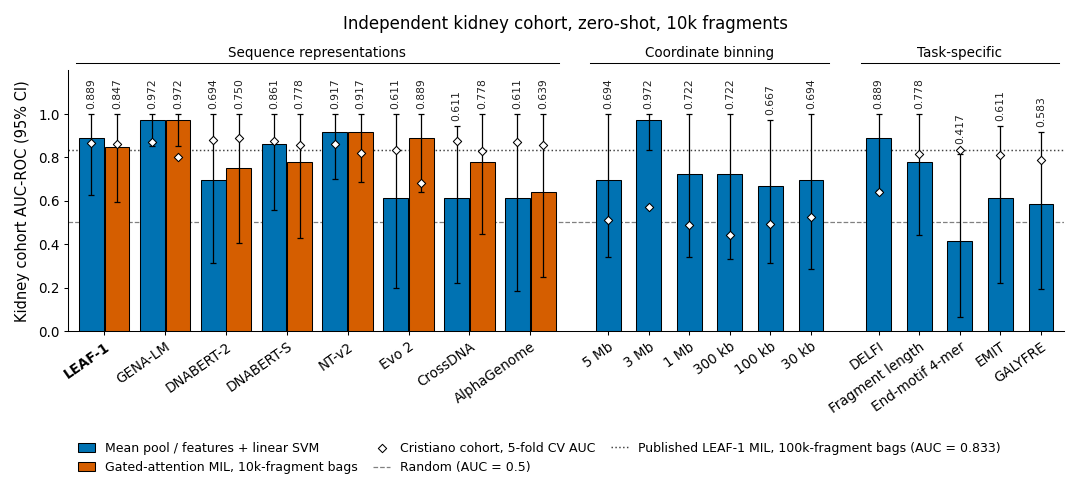

                   group                                     label      arm   auc  auc_lo  auc_hi  cristiano_5fold_auc
Sequence representations                                    LEAF-1      svm 0.889   0.625   1.000                0.864
Sequence representations                                    LEAF-1      mil 0.847   0.593   1.000                0.860
Sequence representations                                   GENA-LM      svm 0.972   0.850   1.000                0.870
Sequence representations                                   GENA-LM      mil 0.972   0.850   1.000                0.800
Sequence representations                                 DNABERT-2      svm 0.694   0.314   1.000                0.881
Sequence representations                                 DNABERT-2      mil 0.750   0.406   1.000                0.889
Sequence representations                                 DNABERT-S      svm 0.861   0.556   1.000                0.874
Sequence representations                        

In [2]:
# ── Figure, as plot_bar_extended.py ───────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

GROUPS = ("Sequence representations", "Coordinate binning", "Task-specific")
ARMS = {"svm": ("Mean pool / features + linear SVM", OKABE_ITO["blue"]),
        "mil": ("Gated-attention MIL, 10k-fragment bags", OKABE_ITO["orange"])}
GAP = 0.6                                   # extra space between groups
STEP = {2: 1.35, 1: 0.90}                   # x slot per model: wide for SVM + MIL pairs
W = 0.55                                    # bar width
FIG6E_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
    "font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
    "axes.spines.top": False, "axes.spines.right": False,
}

t = pd.read_csv(DATA / "cfdna_kidney_zeroshot_auc.csv", float_precision="round_trip")
pub = t[t.arm == "mil-100k"].iloc[0]
tab = t[t.arm.isin(list(ARMS))].reset_index(drop=True)          # table order = plot order
assert list(dict.fromkeys(tab.group)) == list(GROUPS)
assert ((tab.auc_lo <= tab.auc + 1e-9) & (tab.auc_hi >= tab.auc - 1e-9)).all()

# x layout: one slot per model, two bars in the slot when it has both arms
n_arms = tab.groupby("head", sort=False).arm.nunique()
xs, xcs, x, prev = [], [], 0.0, None
for head, group in tab[["head", "group"]].drop_duplicates().itertuples(index=False):
    if prev is not None and group != prev:
        x += GAP
    step = STEP[n_arms[head]]; x += step / 2
    rows = tab[tab["head"] == head]
    offsets = {"svm": -W / 2 - 0.01, "mil": W / 2 + 0.01} if len(rows) == 2 else {"svm": 0.0}
    for arm in rows.arm:
        xs.append((head, arm, x + offsets[arm], x, step))
    x += step / 2; prev = group
pos = pd.DataFrame(xs, columns=["head", "arm", "x", "xc", "step"])
tab = tab.merge(pos, on=["head", "arm"], validate="one_to_one")

with plt.rc_context(FIG6E_RC):
    fig, ax = plt.subplots(figsize=(7.2, 3.2))
    for arm, (lab, color) in ARMS.items():
        r = tab[tab.arm == arm]
        auc, lo, hi = r.auc.to_numpy(), r.auc_lo.to_numpy(), r.auc_hi.to_numpy()
        ax.bar(r.x, auc, width=W, color=color, edgecolor="black", linewidth=0.5,
               yerr=[np.clip(auc - lo, 0, None), np.clip(hi - auc, 0, None)], capsize=1.4,
               error_kw=dict(elinewidth=0.6, ecolor="black", capthick=0.6), label=lab, zorder=3)
        top = np.fmax(hi, r.cristiano_5fold_auc.to_numpy())   # clear of the diamond too
        for xi, value, high in zip(r.x, auc, top):
            ax.text(xi, high + 0.025, f"{value:.3f}", ha="center", va="bottom", rotation=90,
                    fontsize=5.2, color="#222222")
    ax.scatter(tab.x, tab.cristiano_5fold_auc, marker="D", s=8, facecolor="white", edgecolor="black",
               linewidth=0.5, zorder=4, label="Cristiano cohort, 5-fold CV AUC")
    ax.axhline(0.5, color="0.5", linestyle="--", linewidth=0.6, zorder=1, label="Random (AUC = 0.5)")
    ax.axhline(pub.auc, color="0.25", linestyle=":", linewidth=0.7, zorder=1,
               label=f"Published LEAF-1 MIL, 100k-fragment bags (AUC = {pub.auc:.3f})")
    for group in GROUPS:
        sub = tab[tab.group == group]
        half = sub.step.iloc[0] / 2 - 0.05
        x0, x1 = sub.xc.min() - half, sub.xc.max() + half
        ax.plot([x0, x1], [1.235, 1.235], color="black", linewidth=0.5, clip_on=False)
        ax.text((x0 + x1) / 2, 1.25, group, ha="center", va="bottom", fontsize=6.5, linespacing=1.0)
    ticks = tab.drop_duplicates("head")
    ax.set_xticks(ticks.xc); ax.set_xticklabels(ticks.label)
    ax.set_xlim(tab.xc.min() - 0.8, tab.xc.max() + 0.5); ax.set_ylim(0, 1.2)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_ylabel("Kidney cohort AUC-ROC (95% CI)")
    ax.set_title("Independent kidney cohort, zero-shot, 10k fragments", pad=20)
    ax.tick_params(axis="both", which="major", length=2, pad=2)
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", rotation_mode="anchor")  # after tick_params
    ax.get_xticklabels()[0].set_fontweight("bold")
    fig.tight_layout(rect=(0, 0.10, 1, 1))     # room for the legend below the rotated labels
    handles, labels = ax.get_legend_handles_labels()
    want = [ARMS["svm"][0], ARMS["mil"][0], "Cristiano cohort, 5-fold CV AUC", "Random (AUC = 0.5)"] \
        + [l for l in labels if l.startswith("Published")]
    fig.legend([handles[labels.index(l)] for l in want], want, loc="lower center", bbox_to_anchor=(0.5, 0.0),
               ncol=3, frameon=False, handlelength=1.4, borderaxespad=0.0, columnspacing=1.2)
    out = pd.concat([tab[["group", "head", "label", "arm", "auc", "auc_lo", "auc_hi", "cristiano_5fold_auc"]],
                     t[t.arm == "mil-100k"][["head", "label", "arm", "auc", "auc_lo", "auc_hi"]]], ignore_index=True)
    savefig(fig, OUT, "cfdna_kidney_zeroshot_auc_extended", data=out)
    plt.show()
print(out[["group", "label", "arm", "auc", "auc_lo", "auc_hi", "cristiano_5fold_auc"]].round(3).to_string(index=False))
